In [5]:
import sys
sys.path.insert(1, '/home/fainx/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *
from datetime import datetime
import mar
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
import cartopy.crs as ccrs
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import regionmask 
import matplotlib.ticker as ticker

## Data

In [6]:
folder = '/bettik/PROJECTS/pr-regional-climate/fainx/AWS_pamir/'
file = 'CR1000X_Pamir1_iriTable_1h_a.dat'

In [58]:
ds = pd.read_csv(
    folder+file,                     
    sep=",",
    skiprows=[0,2,3],                
    parse_dates=["TIMESTAMP"],
    na_values=["NAN"],
    index_col=None,
)
ds.columns

Index(['TIMESTAMP', 'RECORD', 'Hour', 'AirTemp_Avg', 'WindSpeed_Avg',
       'WindSpeed_Max', 'WindDir_corr', 'RH_Avg', 'SW_in_Avg',
       'SW_reflected_Avg', 'SnowVUE_TCDT', 'Ground_Temp', 'Therm(1)',
       'Therm(2)', 'Therm(3)', 'Therm(4)', 'Therm(5)', 'Therm(6)', 'Therm(7)',
       'Therm(8)', 'Therm(9)', 'Therm(10)', 'Therm(11)', 'Therm(12)',
       'Therm(13)'],
      dtype='object')

In [59]:
ds

,TIMESTAMP,RECORD,Hour,AirTemp_Avg,WindSpeed_Avg,WindSpeed_Max,WindDir_corr,RH_Avg,SW_in_Avg,SW_reflected_Avg,...,Therm(4),Therm(5),Therm(6),Therm(7),Therm(8),Therm(9),Therm(10),Therm(11),Therm(12),Therm(13)
0,2024-10-03 13:00:00,0,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-10-09 13:00:00,1,12,-8.570,3.971,6.11,152.6,93.80,5.417,5.168,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-10-09 14:00:00,2,13,-9.320,2.755,5.88,188.7,92.10,-1.985,0.119,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-10-09 15:00:00,3,14,-11.360,5.260,7.36,186.8,89.30,-1.952,0.245,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-10-09 16:00:00,4,15,-14.170,5.669,7.78,173.7,87.40,-1.590,0.626,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16334,2026-08-23 00:00:00,16334,23,-8.030,4.222,6.21,263.9,49.50,-0.190,-0.007,...,-0.008,-0.148,-0.148,-0.039,0.023,-0.047,0.008,0.016,-0.156,-8.110
16335,2026-08-23 01:00:00,16335,0,-8.110,4.977,8.65,278.0,49.51,7.767,7.855,...,-0.016,-0.148,-0.141,-0.039,0.023,-0.039,0.008,0.008,-0.148,-8.270
16336,2026-08-23 02:00:00,16336,1,-8.490,4.351,7.28,284.7,49.50,82.900,82.000,...,-0.016,-0.156,-0.148,-0.039,0.016,-0.031,0.008,0.016,-0.148,-6.992
16337,2026-08-23 03:00:00,16337,2,-7.970,5.180,8.19,274.9,49.51,239.200,227.100,...,-0.008,-0.148,-0.156,-0.039,0.016,-0.039,0.008,0.016,-0.141,-3.992


## Functions 

In [9]:
def clean_snow_height(df, max_jump=1.0, window=25):
    """Nettoyage du SnowVUE_TCDT :
    1. filtre de persistance : saut > max_jump m par rapport à la dernière
       valeur valide rejeté 
    2. médiane glissante 25 h centrée.
    Retourne une Série (m) alignée sur df."""
    
    tc = df[SNOW_COL].astype(float).copy()
    clean = pd.Series(np.nan, index=tc.index)
    ref = None
    for i, v in enumerate(tc):
        if np.isnan(v):
            continue
        if ref is None or abs(v - ref) <= max_jump:
            clean.iloc[i] = v
            ref = v
    clean = clean.ffill().bfill()
    return clean.rolling(window, center=True, min_periods=1).median()


In [17]:
def valeur_a(date, x, y):
    date = pd.Timestamp(date)
    i = (x - date).abs().idxmin()
    return x[i], y[i]

## Plots

In [32]:
surface = clean_snow_height(ds)          # position SnowVUE (m)
y_surface = -(surface - surface.iloc[0]) # profondeur de la surface, repère absolu

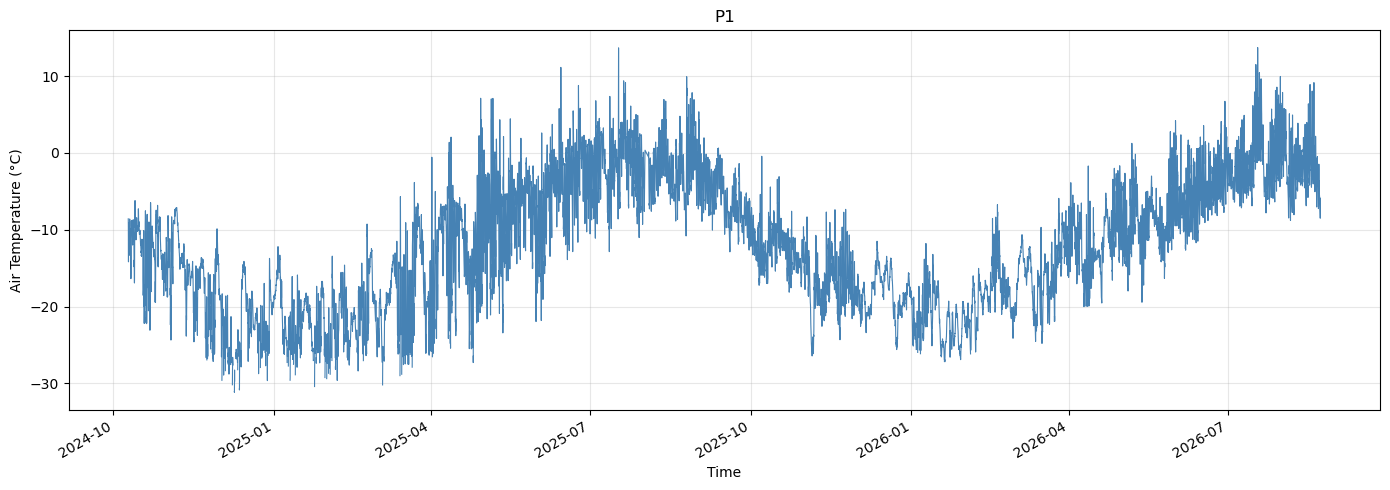

In [33]:
y = pd.to_numeric(ds["AirTemp_Avg"], errors="coerce")
x = pd.to_datetime(ds["TIMESTAMP"])

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(x, y, lw=0.8, color="steelblue")
ax.set_xlabel("Time")
ax.set_ylabel("Air Temperature (°C)")
ax.set_title("P1")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [61]:
surface = clean_snow_height(ds)
y_surface = -(surface - surface.iloc[0])

# Extraire la période souhaitée
y_surface = y_surface.loc["2025-08-08 00:00:00":]

2026    -0.6520
2027    -0.6520
2028    -0.6520
2029    -0.6520
2030    -0.6520
          ...  
16334   -0.0560
16335   -0.0665
16336   -0.0770
16337   -0.0965
16338   -0.1160
Length: 14313, dtype: float64

In [34]:
y = pd.to_numeric(ds["SnowVUE_TCDT"], errors="coerce")
y_filtered = y.rolling(window=20, center=True).median()

for d in ["2025-08-08", "2025-10-01"]:
    t, v = valeur_a(d, x, y_filtered)
    print(f"{t}  →  Snow height = {v:.4f}")

2025-08-08 00:00:00  →  Snow height = -4.4210
2025-10-01 00:00:00  →  Snow height = -5.1975


In [35]:
y = pd.to_numeric(ds["SnowVUE_TCDT"], errors="coerce")
y_filtered = y.rolling(window=20, center=True).median()

for d in ["2025-10-01", "2026-08-22"]:
    t, v = valeur_a(d, x, y_filtered)
    print(f"{t}  →  Snow height = {v:.4f}")

2025-10-01 00:00:00  →  Snow height = -5.1975
2026-08-22 00:00:00  →  Snow height = -3.3465


In [36]:
# net accu between 2025 and 2026 drilling in cm
# Use this number to shift the the two profiles
((4.4210 - 5.1975) + (5.1975 - 3.3465)) * 100

107.45000000000005

In [37]:
# Snow accumulation during 2025/2026 hydrological year
-3.3465 + 5.1975

1.851

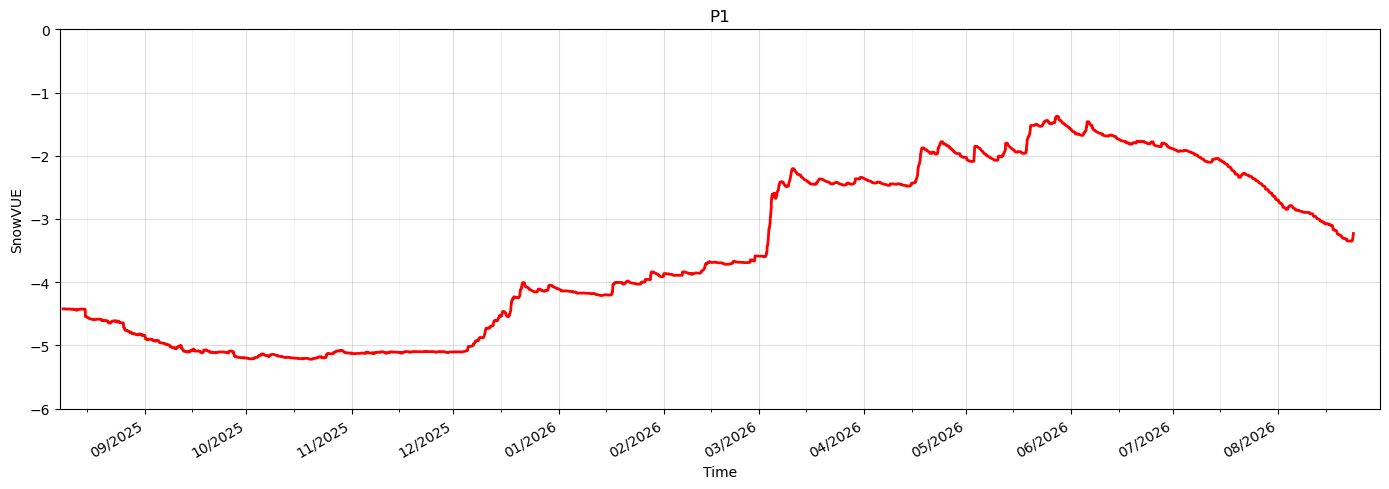

In [38]:
start = "2025-08-07"
stop  = "2026-08-31"

surface = clean_snow_height(df)        # position SnowVUE (m)

x = pd.to_datetime(df["TIMESTAMP"])

# Détecter les variations brutales
delta = y.diff()

# Seuil à ajuster selon tes données
seuil = 1.0

anomalies = delta.abs() > seuil

# Masquer les points anormaux
y_clean = y.mask(anomalies)

# Médiane glissante
y_filtered = y_clean.rolling(
    window=20,
    center=True,
    min_periods=1
).median()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(x, surface, lw=2, color="red")

ax.set_xlim(pd.Timestamp(start), pd.Timestamp(stop))
ax.set_ylim(-6, 0)

# Grille mensuelle
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_minor_locator(
    mdates.MonthLocator(bymonthday=15)
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%m/%Y")
)

ax.grid(which="major", alpha=0.4)
ax.grid(which="minor", alpha=0.15)

ax.set_xlabel("Time")
ax.set_ylabel("SnowVUE")
ax.set_title("P1")

fig.autofmt_xdate()
plt.tight_layout()

fig.savefig(
    "SnowVUE_TCDT.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

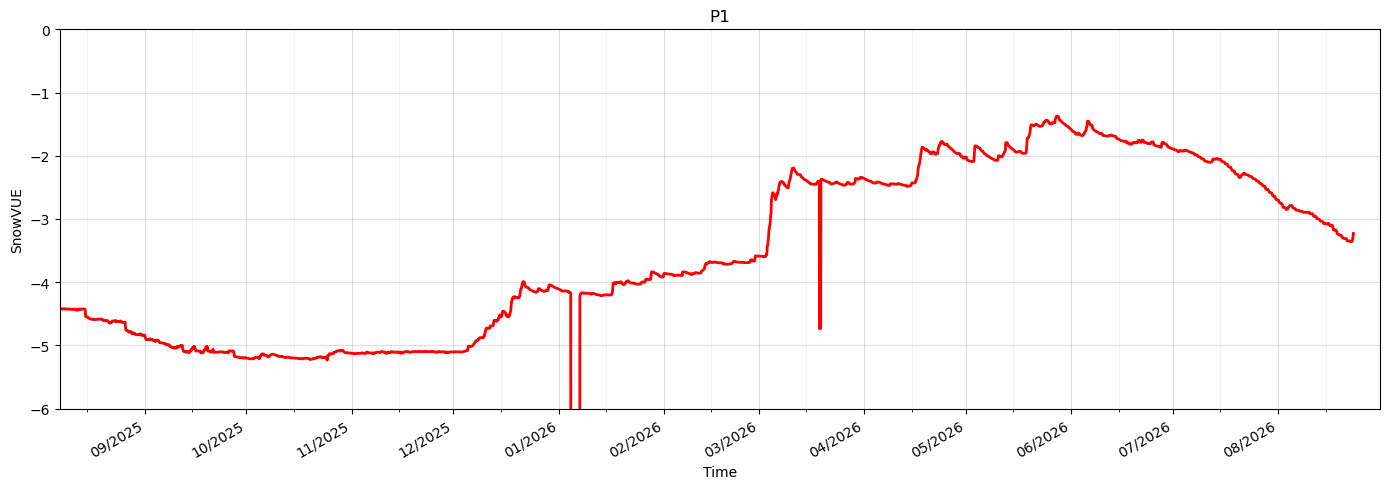

In [39]:
start = "2025-08-07"
stop  = "2026-08-31"

y = pd.to_numeric(ds["SnowVUE_TCDT"], errors="coerce")
x = pd.to_datetime(ds["TIMESTAMP"])

# Détecter les variations brutales
delta = y.diff()

# Seuil à ajuster selon tes données
seuil = 1.0

anomalies = delta.abs() > seuil

# Masquer les points anormaux
y_clean = y.mask(anomalies)

# Médiane glissante
y_filtered = y_clean.rolling(
    window=20,
    center=True,
    min_periods=1
).median()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(x, y_filtered, lw=2, color="red")

ax.set_xlim(pd.Timestamp(start), pd.Timestamp(stop))
ax.set_ylim(-6, 0)

# Grille mensuelle
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_minor_locator(
    mdates.MonthLocator(bymonthday=15)
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%m/%Y")
)

ax.grid(which="major", alpha=0.4)
ax.grid(which="minor", alpha=0.15)

ax.set_xlabel("Time")
ax.set_ylabel("SnowVUE")
ax.set_title("P1")

fig.autofmt_xdate()
plt.tight_layout()

fig.savefig(
    "SnowVUE_TCDT.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


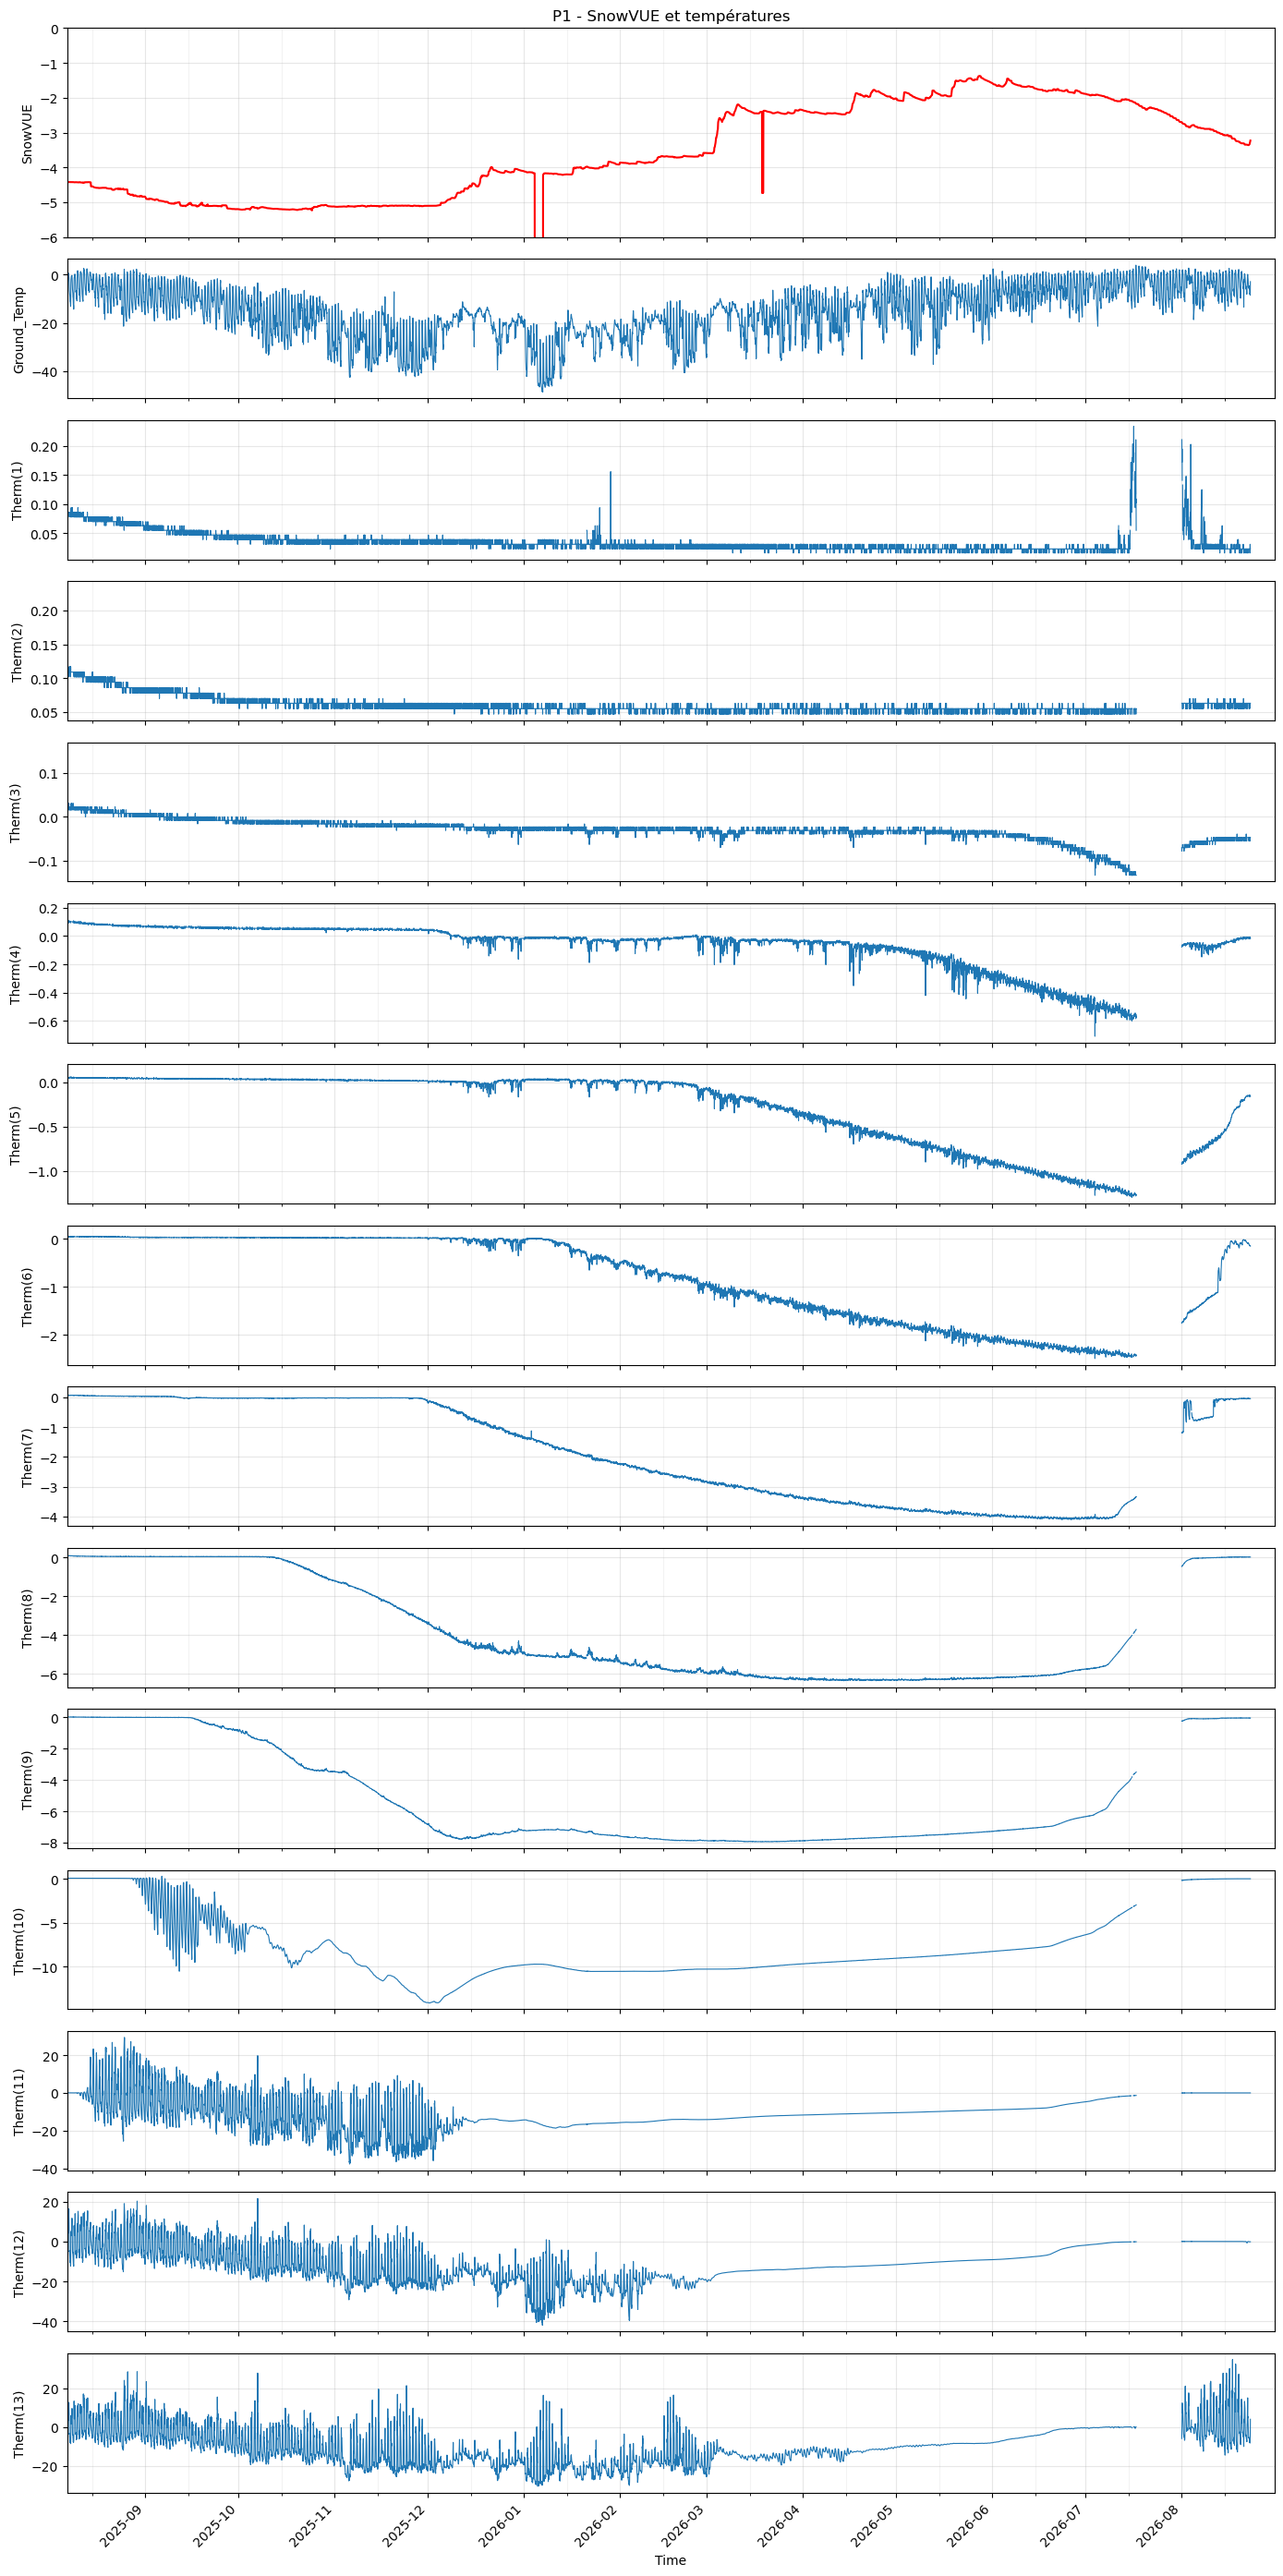

In [41]:
start = "2025-08-07"
stop = "2026-08-31"

x = pd.to_datetime(ds["TIMESTAMP"])

variables = [
    "Ground_Temp",
    "Therm(1)", "Therm(2)", "Therm(3)", "Therm(4)", "Therm(5)",
    "Therm(6)", "Therm(7)", "Therm(8)", "Therm(9)", "Therm(10)",
    "Therm(11)", "Therm(12)", "Therm(13)"
]

fig, axes = plt.subplots(
    len(variables) + 1, 1,
    figsize=(14, 28),
    sharex=True,
    gridspec_kw={"height_ratios": [1.5] + [1] * len(variables)}
)

# Panel SnowVUE en haut
y = pd.to_numeric(ds["SnowVUE_TCDT"], errors="coerce")
anomalies = y.diff().abs() > 1.0
y_filtered = y.mask(anomalies).rolling(
    window=20, center=True, min_periods=1
).median()

axes[0].plot(x, y_filtered, color="red", lw=1.5)
axes[0].set_ylabel("SnowVUE")
axes[0].set_ylim(-6, 0)
axes[0].set_title("P1 - SnowVUE et températures")
axes[0].grid(alpha=0.3)

# Panels température
for ax, var in zip(axes[1:], variables):
    y_var = pd.to_numeric(ds[var], errors="coerce")
    ax.plot(x, y_var, lw=0.8)
    ax.set_ylabel(var)
    ax.grid(alpha=0.3)

# Axe temporel commun
for ax in axes:
    ax.set_xlim(pd.Timestamp(start), pd.Timestamp(stop))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonthday=15))
    ax.grid(which="major", axis="x", alpha=0.3)
    ax.grid(which="minor", axis="x", alpha=0.15)

axes[-1].set_xlabel("Time")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

fig.autofmt_xdate(rotation=45)
plt.tight_layout()

fig.savefig(
    "P1-therm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Profils de température du manteau neigeux 

**Repère absolu** : l'axe y est la profondeur relative à la surface du
8 août 2025 (t0, installation des sondes), **positive vers le bas**.
Les 13 thermistances y occupent des positions FIXES :

La surface de neige, mesurée par le SnowVUE (`SnowVUE_TCDT`), évolue dans
ce repère :
    y_surface(t) = -(SnowVUE_TCDT(t) - SnowVUE_TCDT(t0))

À chaque heure, la température est interpolée linéairement entre sondes
adjacentes **enterrées uniquement** 

XAV field book
Therm 12 : 54 cm above snow
Therm 11 - 1 below snow

In [42]:
for d in ["2025-08-08","2025-09-01","2025-12-15", "2026-03-01", "2026-04-15" ]:
    t, v = valeur_a(d, x, y_filtered)
    print(f"{t}  →  Snow height = {v:.4f}")

2025-08-08 00:00:00  →  Snow height = -4.4210
2025-09-01 00:00:00  →  Snow height = -4.8405
2025-12-15 00:00:00  →  Snow height = -4.5485
2026-03-01 00:00:00  →  Snow height = -3.5885
2026-04-15 00:00:00  →  Snow height = -2.4360


In [43]:
# A verifier
SENSOR_Y = {
    "Therm(1)":  20.0,  "Therm(2)":  15.5, "Therm(3)":  12.5,
    "Therm(4)":  10.5,  "Therm(5)":   8.5, "Therm(6)":   6.5,
    "Therm(7)":   4.5,  "Therm(8)":   3.5, "Therm(9)":   2.5,
    "Therm(10)":  1.5,  "Therm(11)": 0.5, "Therm(12)": -0.54,
    "Therm(13)": -1.5,
}

In [44]:
# Date d'installation des sondes (t0)
T0_DATE = "2025-08-08"

# Bornes de la grille verticale (m) et pas
Y_TOP, Y_BOT = -5, 20.5
DY = 0.25

In [45]:
TIME_COL = "TIMESTAMP"
SNOW_COL = "SnowVUE_TCDT" 

In [57]:
ds

,TIMESTAMP,RECORD,Hour,AirTemp_Avg,WindSpeed_Avg,WindSpeed_Max,WindDir_corr,RH_Avg,SW_in_Avg,SW_reflected_Avg,...,Therm(4),Therm(5),Therm(6),Therm(7),Therm(8),Therm(9),Therm(10),Therm(11),Therm(12),Therm(13)
0,2025-08-08 00:00:00,7214,23,-4.798,2.347,3.39,256.2,54.08,-3.247,1.036,...,0.094,0.055,0.047,0.070,0.078,0.031,0.070,0.055,-12.320,-7.820
1,2025-08-08 01:00:00,7215,0,-4.855,2.750,3.80,259.8,51.59,6.171,7.766,...,0.102,0.055,0.039,0.070,0.078,0.031,0.070,0.055,-11.490,-8.570
2,2025-08-08 02:00:00,7216,1,-4.463,2.540,3.90,258.6,51.72,251.900,162.100,...,0.102,0.055,0.039,0.070,0.078,0.031,0.070,0.063,2.539,-2.148
3,2025-08-08 03:00:00,7217,2,-3.264,1.790,2.60,254.3,49.50,497.500,296.500,...,0.102,0.055,0.039,0.070,0.078,0.023,0.078,0.055,2.852,4.953
4,2025-08-08 04:00:00,7218,3,-2.330,2.055,4.17,260.8,45.69,725.400,397.600,...,0.102,0.055,0.047,0.070,0.078,0.023,0.078,0.063,5.063,5.930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9120,2026-08-23 00:00:00,16334,23,-8.030,4.222,6.21,263.9,49.50,-0.190,-0.007,...,-0.008,-0.148,-0.148,-0.039,0.023,-0.047,0.008,0.016,-0.156,-8.110
9121,2026-08-23 01:00:00,16335,0,-8.110,4.977,8.65,278.0,49.51,7.767,7.855,...,-0.016,-0.148,-0.141,-0.039,0.023,-0.039,0.008,0.008,-0.148,-8.270
9122,2026-08-23 02:00:00,16336,1,-8.490,4.351,7.28,284.7,49.50,82.900,82.000,...,-0.016,-0.156,-0.148,-0.039,0.016,-0.031,0.008,0.016,-0.148,-6.992
9123,2026-08-23 03:00:00,16337,2,-7.970,5.180,8.19,274.9,49.51,239.200,227.100,...,-0.008,-0.148,-0.156,-0.039,0.016,-0.039,0.008,0.016,-0.141,-3.992


In [55]:
def load_data(path):
    """Lecture d'un export TOA5 : ligne 1 = noms de colonnes,
    lignes 2-4 = unités / type / traitement (ignorées)."""
    
    df = pd.read_csv(path, skiprows=[0, 2, 3], na_values=["NAN"])
    df[TIME_COL] = pd.to_datetime(df[TIME_COL])
    df = df.sort_values(TIME_COL).reset_index(drop=True)
    therm_cols = [c for c in df.columns if c in SENSOR_Y]
    assert len(therm_cols) >= 2, "Colonnes Therm(1)...Therm(13) introuvables"
    return df, therm_cols

df, therm_cols = load_data(folder + file)

# Période utile : depuis t0 (installation)
t0 = pd.Timestamp(T0_DATE)
df = df[df[TIME_COL] >= t0].reset_index(drop=True)

print(f"Période : {df[TIME_COL].iloc[0]} -> {df[TIME_COL].iloc[-1]}  ({len(df)} heures)")
df

Période : 2025-08-08 00:00:00 -> 2026-08-23 04:00:00  (9125 heures)


,TIMESTAMP,RECORD,Hour,AirTemp_Avg,WindSpeed_Avg,WindSpeed_Max,WindDir_corr,RH_Avg,SW_in_Avg,SW_reflected_Avg,...,Therm(4),Therm(5),Therm(6),Therm(7),Therm(8),Therm(9),Therm(10),Therm(11),Therm(12),Therm(13)
0,2025-08-08 00:00:00,7214,23,-4.798,2.347,3.39,256.2,54.08,-3.247,1.036,...,0.094,0.055,0.047,0.070,0.078,0.031,0.070,0.055,-12.320,-7.820
1,2025-08-08 01:00:00,7215,0,-4.855,2.750,3.80,259.8,51.59,6.171,7.766,...,0.102,0.055,0.039,0.070,0.078,0.031,0.070,0.055,-11.490,-8.570
2,2025-08-08 02:00:00,7216,1,-4.463,2.540,3.90,258.6,51.72,251.900,162.100,...,0.102,0.055,0.039,0.070,0.078,0.031,0.070,0.063,2.539,-2.148
3,2025-08-08 03:00:00,7217,2,-3.264,1.790,2.60,254.3,49.50,497.500,296.500,...,0.102,0.055,0.039,0.070,0.078,0.023,0.078,0.055,2.852,4.953
4,2025-08-08 04:00:00,7218,3,-2.330,2.055,4.17,260.8,45.69,725.400,397.600,...,0.102,0.055,0.047,0.070,0.078,0.023,0.078,0.063,5.063,5.930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9120,2026-08-23 00:00:00,16334,23,-8.030,4.222,6.21,263.9,49.50,-0.190,-0.007,...,-0.008,-0.148,-0.148,-0.039,0.023,-0.047,0.008,0.016,-0.156,-8.110
9121,2026-08-23 01:00:00,16335,0,-8.110,4.977,8.65,278.0,49.51,7.767,7.855,...,-0.016,-0.148,-0.141,-0.039,0.023,-0.039,0.008,0.008,-0.148,-8.270
9122,2026-08-23 02:00:00,16336,1,-8.490,4.351,7.28,284.7,49.50,82.900,82.000,...,-0.016,-0.156,-0.148,-0.039,0.016,-0.031,0.008,0.016,-0.148,-6.992
9123,2026-08-23 03:00:00,16337,2,-7.970,5.180,8.19,274.9,49.51,239.200,227.100,...,-0.008,-0.148,-0.156,-0.039,0.016,-0.039,0.008,0.016,-0.141,-3.992


In [56]:
y_surface

0       -0.0000
1        0.0010
2        0.0020
3        0.0030
4        0.0040
          ...  
16334   -0.0560
16335   -0.0665
16336   -0.0770
16337   -0.0965
16338   -0.1160
Length: 16339, dtype: float64

In [53]:
def build_profiles(df, y_surface, therm_cols, y_top, y_bot, dy=0.25):
    """
    Interpolation linéaire entre sondes adjacentes, heure par heure,
    dans le repère absolu (capteurs fixes, profondeur positive vers le bas).

    - seules les sondes sous la surface participent (y_sens >= y_surface) ;
    - interpolation uniquement entre les sondes valides extrêmes ;
    - aucune extrapolation hors de la plage des sondes ;
    - zone au-dessus de la surface laissée en NaN (air).

    Retourne (y_grid, temp_grid, y_sens).
    temp_grid a la forme (n_temps, ny).
    """

    # Positions fixes des capteurs
    y_sens = np.array([SENSOR_Y[c] for c in therm_cols], dtype=float)

    ys = y_surface.to_numpy(dtype=float)
    temps_meas = df[therm_cols].to_numpy(dtype=float)

    # Grille verticale
    y_grid = np.arange(y_top, y_bot + dy, dy)

    n_t = len(df)
    temp_grid = np.full((n_t, y_grid.size), np.nan)

    for k in range(n_t):

        # Capteurs valides et enterrés
        ok = (
            np.isfinite(temps_meas[k])
            & (y_sens >= ys[k] - 1e-3)
        )

        # Il faut au moins deux capteurs pour interpoler
        if ok.sum() < 2:
            continue

        # Trier les capteurs par profondeur
        order = np.argsort(y_sens[ok])
        y_ok = y_sens[ok][order]
        T_ok = temps_meas[k][ok][order]

        # Grille située sous la surface ET entre les capteurs extrêmes
        in_range = (
            (y_grid >= ys[k] - 1e-3)
            & (y_grid >= y_ok[0])
            & (y_grid <= y_ok[-1])
        )

        # Interpolation uniquement dans cette plage
        temp_grid[k, in_range] = np.interp(
            y_grid[in_range],
            y_ok,
            T_ok
        )

    return y_grid, temp_grid, y_sens


# Reconstruction des profils
y_grid, temp_grid, y_sens = build_profiles(
    df,
    y_surface,
    therm_cols,
    Y_TOP,
    Y_BOT,
    dy=DY
)

ValueError: x and y must have same first dimension, but have shapes (9125,) and (16339,)

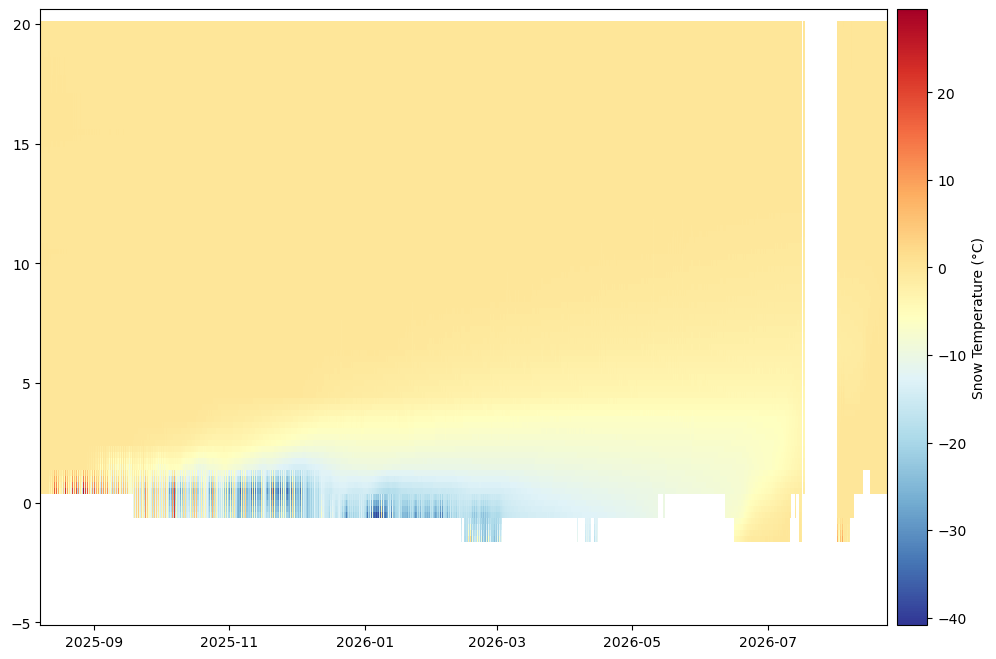

In [54]:
def plot_figure4(df, y_grid, temp_grid, y_surface, y_sens=None,
                 cmap="RdYlBu_r", figsize=(13, 8), outfile="figure4_temperature.png"):

    times = df[TIME_COL]
    ys = y_surface.to_numpy(float)

    fig, ax = plt.subplots(figsize=figsize)

    # champ de température (NaN = air -> cellules vides)
    mesh = ax.pcolormesh(times, y_grid, temp_grid.T,
                         cmap=cmap, shading="auto")
    cbar = fig.colorbar(mesh, ax=ax, pad=0.01)
    cbar.set_label("Snow Temperature (°C)")

    # ligne de surface de neige (évolution réelle)
    ax.plot(times, ys, color="k", lw=2.2,)

    # positions fixes des thermistances (tirets) + annotations
    if y_sens is not None:
        for yy in y_sens:
            ax.axhline(yy, color="k", lw=0.4, alpha=0.3)
        # après inversion : haut du graphe = air (−1,5 m), bas = +20 m
#        ax.annotate("Therm13 (−1,2 m, air à t₀)", xy=(0.005, 0.965),
#                    xycoords="axes fraction", fontsize=9, va="top")
#        ax.annotate("Therm10 (0 m, surface à t₀)", xy=(0.005, 0.60),
#                    xycoords="axes fraction", fontsize=9, va="top")
#        ax.annotate("Therm1 (+20 m, profond)", xy=(0.005, 0.035),
#                    xycoords="axes fraction", fontsize=9, va="bottom")

    ax.set_ylabel("Depth (m)")
    # axe INVERSÉ : −1,5 m (air) en haut, +20 m (Therm1, profond) en bas
    ax.set_ylim(20,-5)
#    ax.legend(loc="lower left", framealpha=0.9)
    ax.set_title("P1, Jasgulem Pass")
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    fig.autofmt_xdate()
    fig.tight_layout()
    
    fig.savefig(outfile, dpi=300)
    print(f"Figure enregistrée : {outfile}")
    return fig

fig = plot_figure4(df, y_grid, temp_grid, y_surface, y_sens=y_sens)
plt.show()

In [ ]:
def plot_single_profile(df, y_surface, therm_cols, when):
    """Profil interpolé à un instant donné, dans le même repère absolu
    (0 = surface à t0, profondeur positive vers le bas)."""
    idx = (df[TIME_COL] - pd.Timestamp(when)).abs().idxmin()
    y_sens = np.array([SENSOR_Y[c] for c in therm_cols])
    ys = y_surface.iloc[idx]
    T = df.loc[idx, therm_cols].to_numpy(float)
    ok = (~np.isnan(T)) & (y_sens >= ys - 1e-3)     # sondes enterrées
    y, Ts = y_sens[ok], T[ok]
    order = np.argsort(y)
    y, Ts = y[order], Ts[order]
    yy = np.arange(ys, y.max() + 0.05, 0.05)        # depuis la surface réelle
    TT = np.interp(yy, y, Ts)

    fig, ax = plt.subplots(figsize=(4.5, 6))
    ax.plot(TT, yy, "k-")
    ax.plot(Ts, y, "ro", ms=5, label="thermistances")
    ax.axvline(0, color="b", ls=":", lw=1)
    ax.set_xlabel("Température (°C)")
    ax.set_ylabel("Profondeur (m, repère absolu)")
    ax.invert_yaxis()                                # surface en haut
    ax.set_title(f"Profil du {df.loc[idx, TIME_COL]}\n"
                 f"(surface à {ys:.2f} m)")
    ax.legend()
    fig.tight_layout()
    return fig

# Exemple :
fig = plot_single_profile(df, y_surface, therm_cols, "2026-01-15 12:00")